In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [75]:
print(f"DataFrame shape: {df.shape}")
print("\nDataFrame columns:")
print(df.columns.tolist())
print("\nFirst 5 rows of the DataFrame:")
display(df.head())
print("\nData types of each column:")
display(df.info())

DataFrame shape: (123, 15)

DataFrame columns:
['car_id', 'brand', 'model', 'year', 'price_inr', 'km_driven', 'fuel_type', 'transmission', 'owner_type', 'mileage_kmpl', 'engine_cc', 'city', 'insurance_valid', 'seller_rating', 'listed_date']

First 5 rows of the DataFrame:


,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
0,CAR001,maruti,Baleno,2009,236000.0,13300,petrol,manual,1st,12.9,1000.0,hyderabad,Yes,3.1,02-02-2026
1,CAR002,MARUTI,i20,2010,292000.0,17600,Diesel,Automatic,Second,13.8,1200.0,Hyd,Yes,3.2,03-03-2026
2,CAR003,Hyundai,Creta,2011,348000.0,21900,diesel,Auto,2nd,14.7,1400.0,Bangalore,Yes,3.3,04-04-2026
3,CAR004,hyundai,Nexon,2012,404000.0,26200,CNG,AUTOMATIC,Third,15.6,1600.0,Bengaluru,NO,3.4,05-05-2026
4,CAR005,Tata,XUV300,2013,460000.0,30500,Electric,Manual,3rd,16.5,1800.0,Mumbai,Yes,3.5,06-06-2026



Data types of each column:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   car_id           123 non-null    object 
 1   brand            116 non-null    object 
 2   model            123 non-null    object 
 3   year             123 non-null    object 
 4   price_inr        118 non-null    float64
 5   km_driven        123 non-null    object 
 6   fuel_type        123 non-null    object 
 7   transmission     120 non-null    object 
 8   owner_type       123 non-null    object 
 9   mileage_kmpl     118 non-null    float64
 10  engine_cc        119 non-null    float64
 11  city             123 non-null    object 
 12  insurance_valid  123 non-null    object 
 13  seller_rating    123 non-null    float64
 14  listed_date      123 non-null    object 
dtypes: float64(4), object(11)
memory usage: 14.5+ KB


None

### Checking for Missing Values

In [76]:
missing_values = df.isnull().sum()
print("Columns with missing values:")
print(missing_values[missing_values > 0])

Columns with missing values:
brand           7
price_inr       5
transmission    3
mileage_kmpl    5
engine_cc       4
dtype: int64


### Checking for Duplicate Rows

In [77]:
duplicate_rows = df[df.duplicated()]
print(f"Number of duplicate rows found: {len(duplicate_rows)}")
if not duplicate_rows.empty:
    print("\nDuplicate Rows:")
    display(duplicate_rows)

Number of duplicate rows found: 3

Duplicate Rows:


,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
120,CAR012,Maruti,i20,2020,789000.0,60600,Electric,Automatic,First,13.8,1600.0,Hyd,NO,4.2,13-01-2026
121,CAR038,NaN,Innova,2012,865000.0,39100,diesel,Auto,Second,19.2,2000.0,Delhi,Yes,4.7,12-03-2026
122,CAR075,Hyundai,XUV300,2015,366000.0,64900,Electric,Manual,2nd,16.5,1400.0,Mumbai,Yes,4.2,31/02/2025


### Removing Duplicate Rows

In [78]:
initial_rows = df.shape[0]
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

removed_rows = initial_rows - df.shape[0]
print(f"Successfully removed {removed_rows} duplicate rows.")
print(f"New DataFrame shape: {df.shape}")

Successfully removed 3 duplicate rows.
New DataFrame shape: (120, 15)


### Checking for Inconsistent Categories

In [79]:
print("Unique values in 'brand' column before cleaning:")
print(df['brand'].unique())

Unique values in 'brand' column before cleaning:
['maruti' 'MARUTI' 'Hyundai' 'hyundai ' 'Tata' 'TATA' 'Mahindra' 'Kia'
 'Renault' 'Toyota' 'Toyta' 'Maruti' nan]


In [80]:
df['brand'] = df['brand'].str.lower().str.strip()
print("Unique values in 'brand' column after cleaning (lowercase and stripped whitespace):")
print(df['brand'].unique())

Unique values in 'brand' column after cleaning (lowercase and stripped whitespace):
['maruti' 'hyundai' 'tata' 'mahindra' 'kia' 'renault' 'toyota' 'toyta' nan]


In [81]:
# Correct the misspelling 'toyta' to 'toyota' in the 'brand' column
df['brand'] = df['brand'].replace('toyta', 'toyota')
print(df['brand'].unique())

['maruti' 'hyundai' 'tata' 'mahindra' 'kia' 'renault' 'toyota' nan]


In [82]:

print("Unique values in 'fuel_type' column before cleaning:")
print(df['fuel_type'].unique())

Unique values in 'fuel_type' column before cleaning:
['petrol' 'Diesel' 'diesel ' 'CNG' 'Electric' 'PETROL' 'Petrol']


In [83]:

df['fuel_type'] = df['fuel_type'].str.lower().str.strip()

print("Unique values in 'fuel_type' column after cleaning:")
print(df['fuel_type'].unique())

Unique values in 'fuel_type' column after cleaning:
['petrol' 'diesel' 'cng' 'electric']


In [84]:

print("Unique values in 'transmission' column before cleaning:")
print(df['transmission'].unique())

Unique values in 'transmission' column before cleaning:
['manual' 'Automatic' 'Auto' 'AUTOMATIC' 'Manual' nan]


In [85]:
df['transmission'] = df['transmission'].str.lower()
df['transmission'] = df['transmission'].replace('auto', 'automatic')


print("Unique values in 'transmission' column after cleaning:")
print(df['transmission'].unique())

Unique values in 'transmission' column after cleaning:
['manual' 'automatic' nan]


In [86]:
print("Unique values in 'owner_type' column before cleaning:")
print(df['owner_type'].unique())

Unique values in 'owner_type' column before cleaning:
['1st' 'Second' '2nd' 'Third' '3rd' 'First']


In [87]:
# Clean 'owner_type' column by standardizing values
df['owner_type'] = df['owner_type'].str.lower().str.strip()
mapping = {'first': '1st', 'second': '2nd', 'third': '3rd'}
df['owner_type'] = df['owner_type'].replace(mapping)

# Check unique values in 'owner_type' column after cleaning
print("Unique values in 'owner_type' column after cleaning:")
print(df['owner_type'].unique())

Unique values in 'owner_type' column after cleaning:
['1st' '2nd' '3rd']


In [88]:
print("Unique values in 'city' column before cleaning:")
print(df['city'].unique())

Unique values in 'city' column before cleaning:
['hyderabad' 'Hyd' 'Bangalore' 'Bengaluru' 'Mumbai' 'Pune' 'Chennai'
 'Delhi' 'New Delhi' 'Hyderabad']


In [89]:
# Clean 'city' column by standardizing values
df['city'] = df['city'].str.lower().str.strip()
mapping_city = {
    'hyd': 'hyderabad',
    'bangalore': 'bengaluru',
    'new delhi': 'delhi'
}
df['city'] = df['city'].replace(mapping_city)


print("Unique values in 'city' column after cleaning:")
print(df['city'].unique())

Unique values in 'city' column after cleaning:
['hyderabad' 'bengaluru' 'mumbai' 'pune' 'chennai' 'delhi']


In [90]:
print("Unique values in 'insurance_valid' column before cleaning:")
print(df['insurance_valid'].unique())

Unique values in 'insurance_valid' column before cleaning:
['Yes' 'NO' 'Yes ']


In [91]:

df['insurance_valid'] = df['insurance_valid'].str.lower().str.strip()

print("Unique values in 'insurance_valid' column after cleaning:")
print(df['insurance_valid'].unique())

Unique values in 'insurance_valid' column after cleaning:
['yes' 'no']


### Dataset Overview: Shape, Columns, Sample Rows, and Data Types

In [92]:
print(f"DataFrame shape: {df.shape}")print("\nDataFrame columns:")
print(df.columns.tolist())
print("\nFirst 5 rows of the DataFrame:")
display(df.head())
print("\nData types of each column:")
display(df.info())

SyntaxError: invalid syntax (1723824325.py, line 1)

### Descriptive Statistics for Numerical Columns

In [93]:
numerical_cols = df.select_dtypes(include=['number']).columns

print("Descriptive statistics for numerical columns:")
display(df[numerical_cols].describe().T)

Descriptive statistics for numerical columns:


,count,mean,std,min,25%,50%,75%,max
price_inr,115.0,801713.043478,878051.458801,189000.0,455500.000,724000.00,992500.000,9500000.0
mileage_kmpl,115.0,16.108696,2.622927,12.0,13.800,16.50,18.300,20.1
engine_cc,116.0,1503.448276,460.232651,800.0,1150.000,1500.00,1850.000,2200.0
seller_rating,120.0,4.200000,1.103851,3.0,3.575,4.05,4.525,8.7


### Descriptive Statistics for Categorical Columns

In [94]:
categorical_cols = df.select_dtypes(include=['object']).columns

print("Descriptive statistics for categorical columns:")
for col in categorical_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False))

Descriptive statistics for categorical columns:

--- car_id ---


,count
car_id,
CAR001,1
CAR002,1
CAR003,1
CAR004,1
CAR005,1
...,...
CAR116,1
CAR117,1
CAR118,1



--- brand ---


,count
brand,
maruti,29
hyundai,19
tata,19
toyota,19
kia,10
mahindra,9
renault,9
NaN,6



--- model ---


...

,count
city,
hyderabad,36
bengaluru,24
delhi,24
mumbai,12
pune,12
chennai,12



--- insurance_valid ---


,count
insurance_valid,
yes,93
no,27



--- listed_date ---


,count
listed_date,
31/02/2025,4
03-03-2026,2
04-04-2026,2
05-05-2026,2
06-06-2026,2
...,...
24-09-2026,1
25-10-2026,1
26-11-2026,1


### Handling Missing Values

In [95]:
# Impute missing values in 'brand' with its mode
mode_brand = df['brand'].mode()[0]
df['brand'].fillna(mode_brand, inplace=True)
print(f"Missing values in 'brand' imputed with mode: {mode_brand}")

# Impute missing values in 'transmission' with its mode
mode_transmission = df['transmission'].mode()[0]
df['transmission'].fillna(mode_transmission, inplace=True)
print(f"Missing values in 'transmission' imputed with mode: {mode_transmission}")

# Impute missing values in numerical columns ('price_inr', 'mileage_kmpl', 'engine_cc') with their medians
median_price_inr = df['price_inr'].median()
df['price_inr'].fillna(median_price_inr, inplace=True)
print(f"Missing values in 'price_inr' imputed with median: {median_price_inr}")

median_mileage_kmpl = df['mileage_kmpl'].median()
df['mileage_kmpl'].fillna(median_mileage_kmpl, inplace=True)
print(f"Missing values in 'mileage_kmpl' imputed with median: {median_mileage_kmpl}")

median_engine_cc = df['engine_cc'].median()
df['engine_cc'].fillna(median_engine_cc, inplace=True)
print(f"Missing values in 'engine_cc' imputed with median: {median_engine_cc}")

# Verify no more missing values in these columns
print("\nMissing values after imputation:")
print(df[['brand', 'transmission', 'price_inr', 'mileage_kmpl', 'engine_cc']].isnull().sum())

Missing values in 'brand' imputed with mode: maruti
Missing values in 'transmission' imputed with mode: automatic
Missing values in 'price_inr' imputed with median: 724000.0
Missing values in 'mileage_kmpl' imputed with median: 16.5
Missing values in 'engine_cc' imputed with median: 1500.0

Missing values after imputation:
brand           0
transmission    0
price_inr       0
mileage_kmpl    0
engine_cc       0
dtype: int64


/tmp/ipykernel_1041/4168357522.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['brand'].fillna(mode_brand, inplace=True)
/tmp/ipykernel_1041/4168357522.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usin

### Correcting Data Types

In [96]:
# Convert to integer
df['year'] = pd.to_numeric(df['year'], errors='coerce').astype('Int64')
print("Converted 'year' to integer type.")
df['km_driven'] = df['km_driven'].astype(str).str.replace(r'[km,]', '', regex=True).str.strip()
df['km_driven'] = pd.to_numeric(df['km_driven'], errors='coerce').astype('Int64')
print("Converted 'km_driven' to integer type.")

# Convert 'listed_date' to datetime objects
df['listed_date'] = pd.to_datetime(df['listed_date'], dayfirst=True, errors='coerce')
print("Converted 'listed_date' to datetime type.")

# Display data types after conversion to verify
print("\nData types after conversion:")
display(df.info())

Converted 'year' to integer type.
Converted 'km_driven' to integer type.
Converted 'listed_date' to datetime type.

Data types after conversion:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   car_id           120 non-null    object        
 1   brand            120 non-null    object        
 2   model            120 non-null    object        
 3   year             116 non-null    Int64         
 4   price_inr        120 non-null    float64       
 5   km_driven        120 non-null    Int64         
 6   fuel_type        120 non-null    object        
 7   transmission     120 non-null    object        
 8   owner_type       120 non-null    object        
 9   mileage_kmpl     120 non-null    float64       
 10  engine_cc        120 non-null    float64       
 11  city             120 non-null    object        
 12  ins

None

### Handling Remaining Missing Values in 'year' and 'listed_date'

In [97]:
# Impute missing values in 'year' with its median
median_year = df['year'].median()
df['year'].fillna(median_year, inplace=True)
print(f"Missing values in 'year' imputed with median: {median_year}")

# Impute missing values in 'listed_date' with its mode
mode_listed_date = df['listed_date'].mode()[0]
df['listed_date'].fillna(mode_listed_date, inplace=True)
print(f"Missing values in 'listed_date' imputed with mode: {mode_listed_date}")

# Verify no more missing values in these columns and check final info
print("\nMissing values after final imputation:")
print(df[['year', 'listed_date']].isnull().sum())
print("\nFinal DataFrame Info after all cleaning steps:")
display(df.info())

Missing values in 'year' imputed with median: 2016.0
Missing values in 'listed_date' imputed with mode: 2026-01-13 00:00:00

Missing values after final imputation:
year           0
listed_date    0
dtype: int64

Final DataFrame Info after all cleaning steps:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   car_id           120 non-null    object        
 1   brand            120 non-null    object        
 2   model            120 non-null    object        
 3   year             120 non-null    Int64         
 4   price_inr        120 non-null    float64       
 5   km_driven        120 non-null    Int64         
 6   fuel_type        120 non-null    object        
 7   transmission     120 non-null    object        
 8   owner_type       120 non-null    object        
 9   mileage_kmpl     120 non-null    float64       


/tmp/ipykernel_1041/1436801977.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['year'].fillna(median_year, inplace=True)
/tmp/ipykernel_1041/1436801977.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usin

None

## 5. Performing Univariate, Bivariate, and Multivariate Analysis

### Univariate Analysis

#### Numerical Columns Distribution

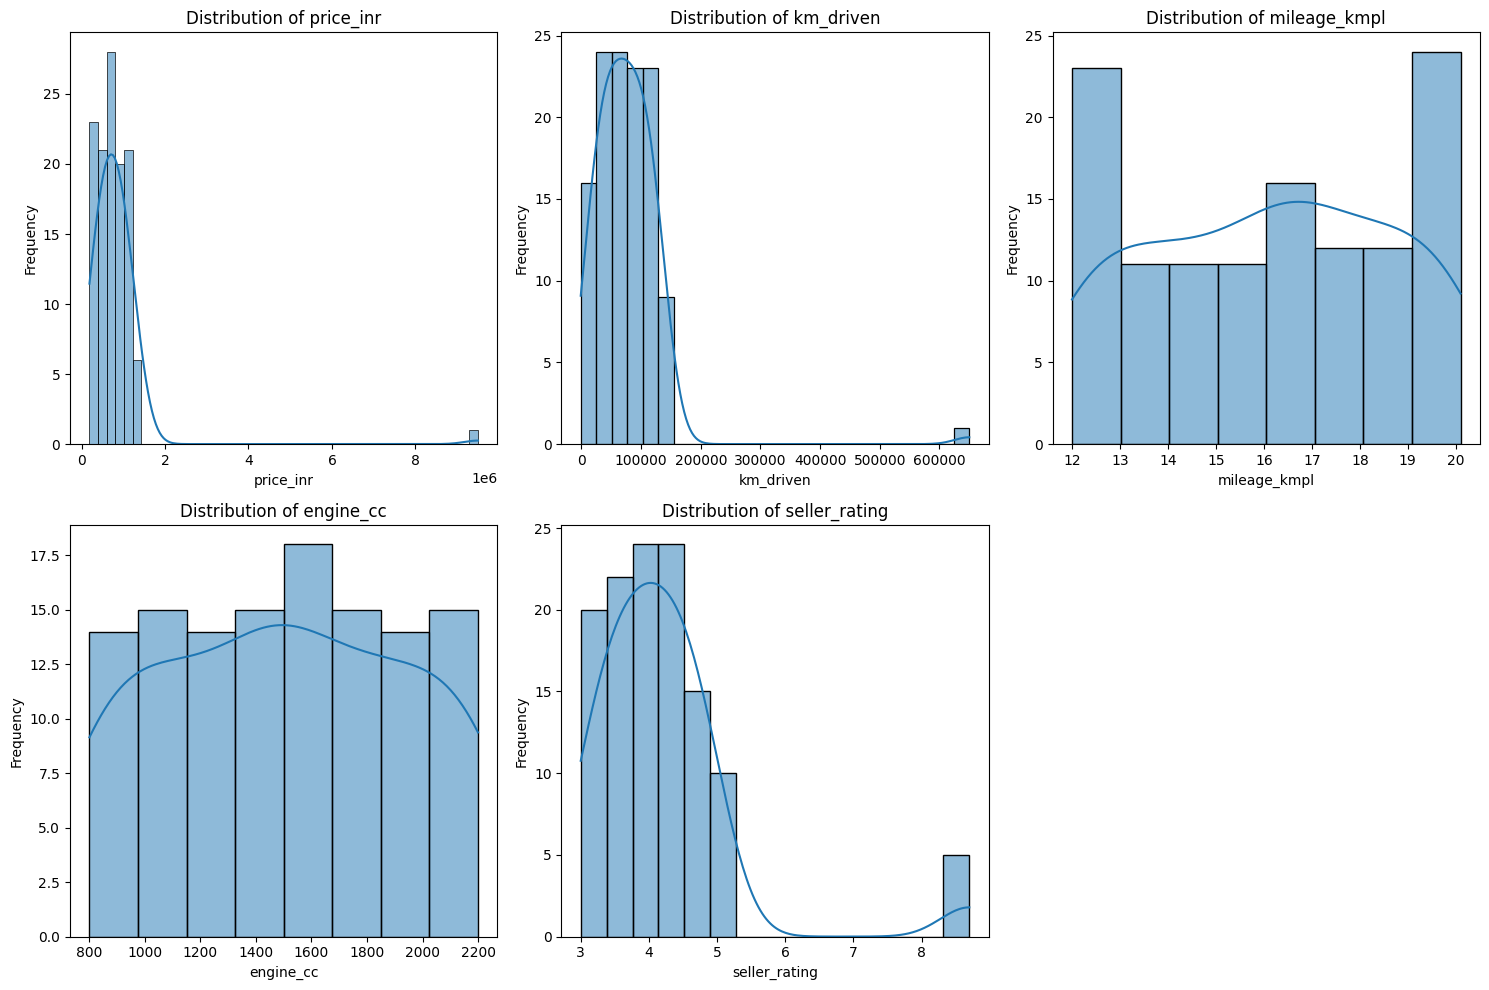

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols_for_analysis = ['price_inr', 'km_driven', 'mileage_kmpl', 'engine_cc', 'seller_rating']

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols_for_analysis):
    plt.subplot(2, 3, i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


#### Categorical Columns Distribution

/tmp/ipykernel_1041/1580537469.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df[col], order = df[col].value_counts().index, palette='viridis')
/tmp/ipykernel_1041/1580537469.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df[col], order = df[col].value_counts().index, palette='viridis')
/tmp/ipykernel_1041/1580537469.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df[col], order = df[col].value_counts().index, palette='viridis')
/tmp/ipykernel_1041/1580537469.py:6: FutureWarning: 

Passing `palette` without assignin

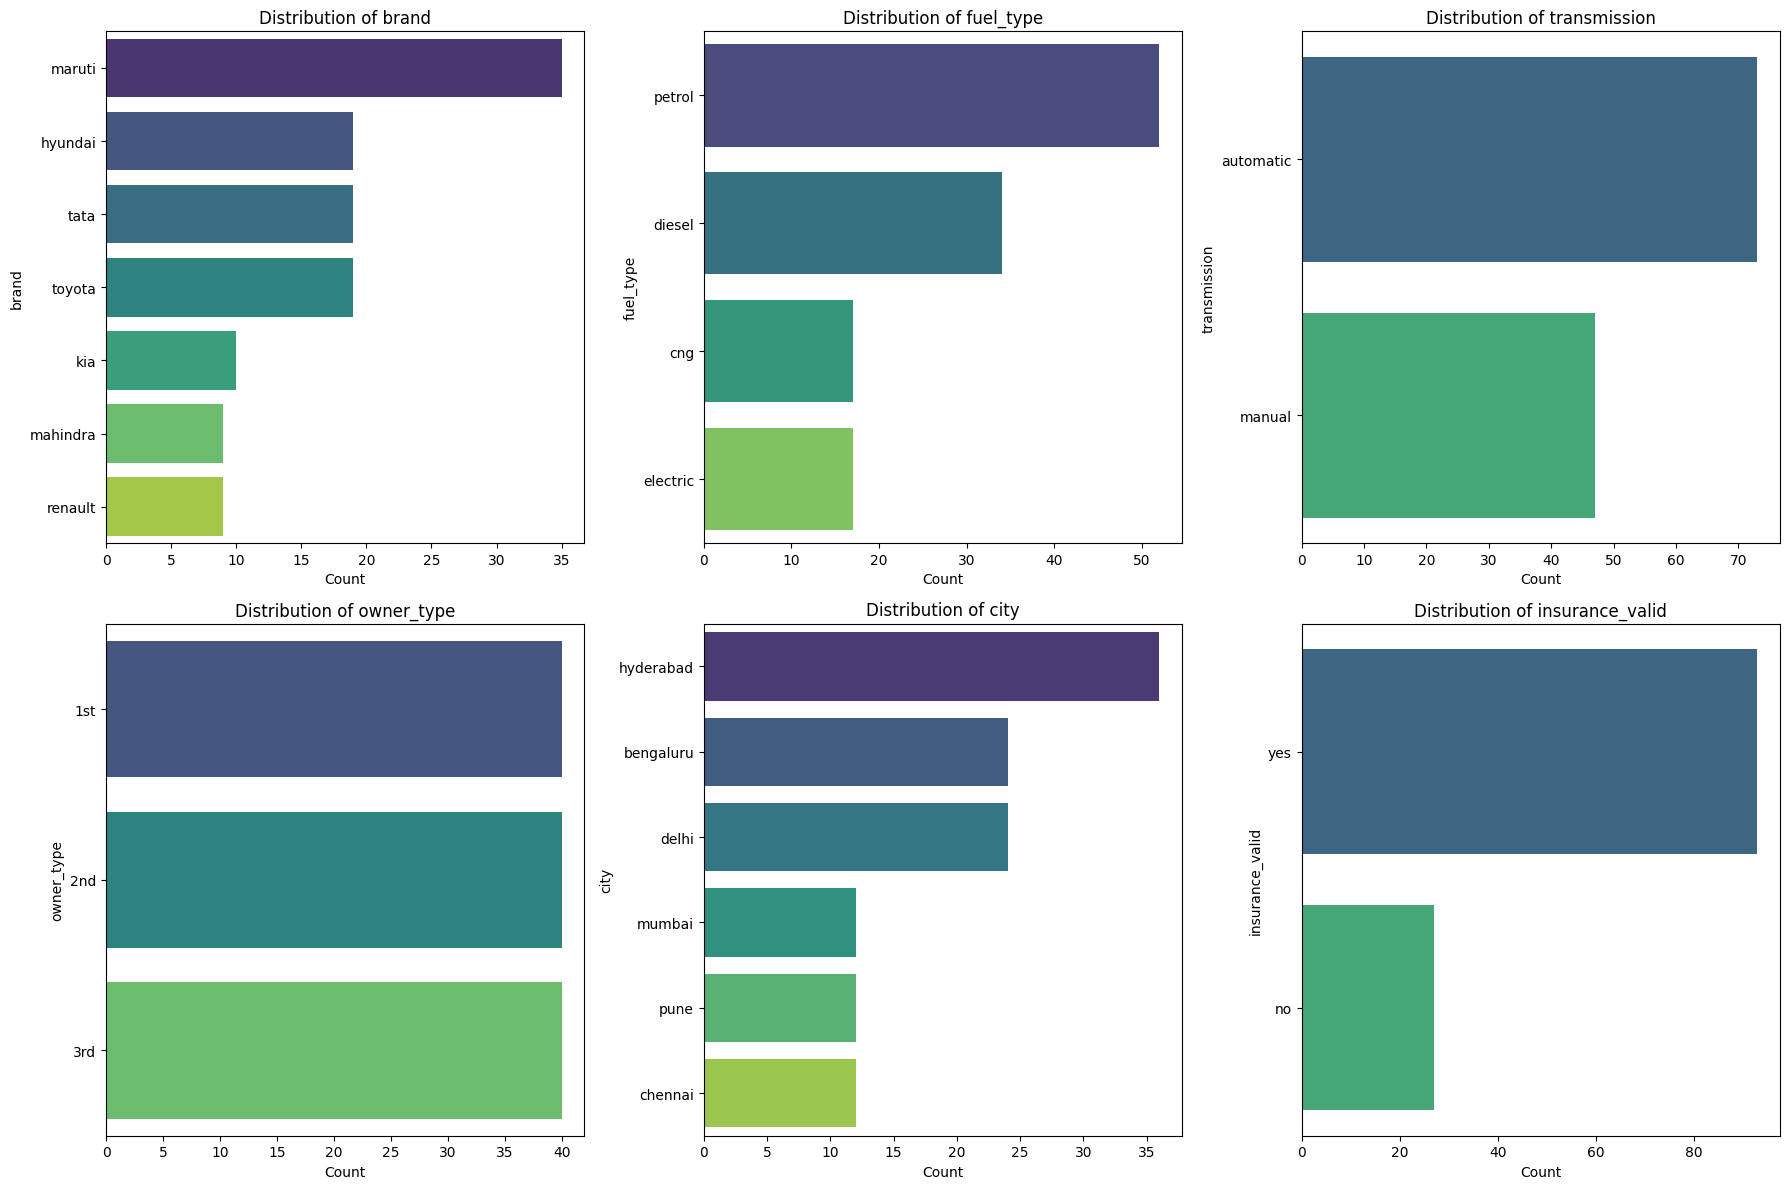

In [99]:
categorical_cols_for_analysis = ['brand', 'fuel_type', 'transmission', 'owner_type', 'city', 'insurance_valid']

plt.figure(figsize=(18, 12))
for i, col in enumerate(categorical_cols_for_analysis):
    plt.subplot(2, 3, i + 1)
    sns.countplot(y=df[col], order = df[col].value_counts().index, palette='viridis')
    plt.title(f'Distribution of {col}')
    plt.xlabel('Count')
    plt.ylabel(col)
plt.tight_layout()
plt.show()


### Bivariate Analysis

#### Numerical vs. Numerical Columns

Pairplot of numerical columns:


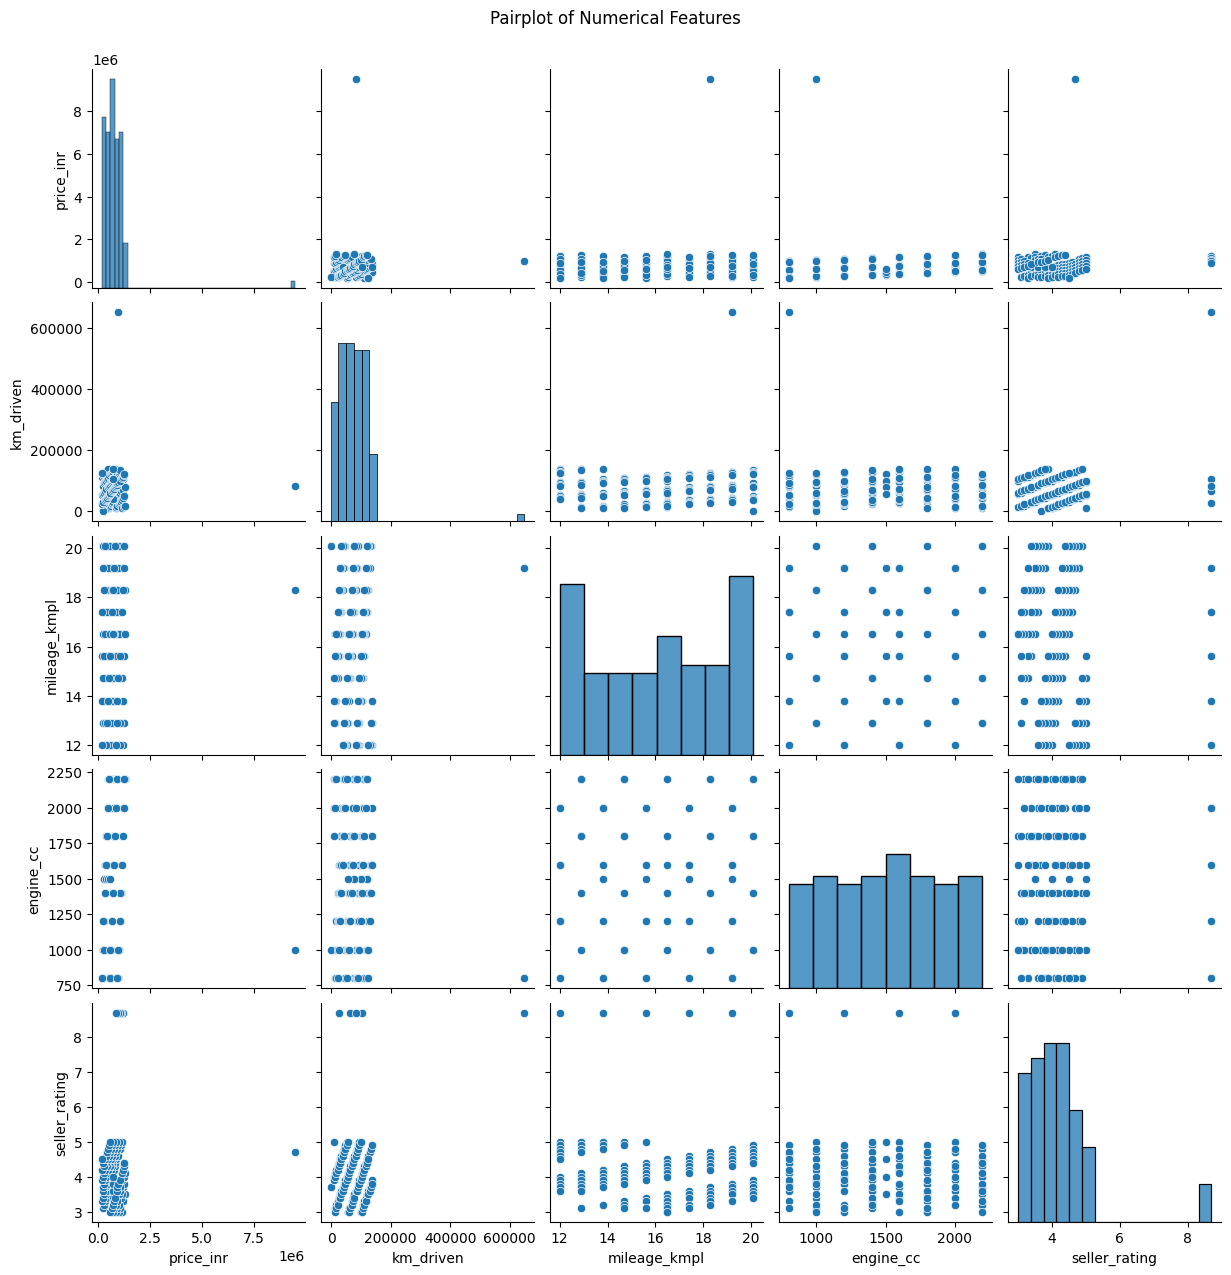

In [100]:
# Pairplot for selected numerical columns to visualize relationships
print("Pairplot of numerical columns:")
sns.pairplot(df[numerical_cols_for_analysis])
plt.suptitle('Pairplot of Numerical Features', y=1.02)
plt.show()

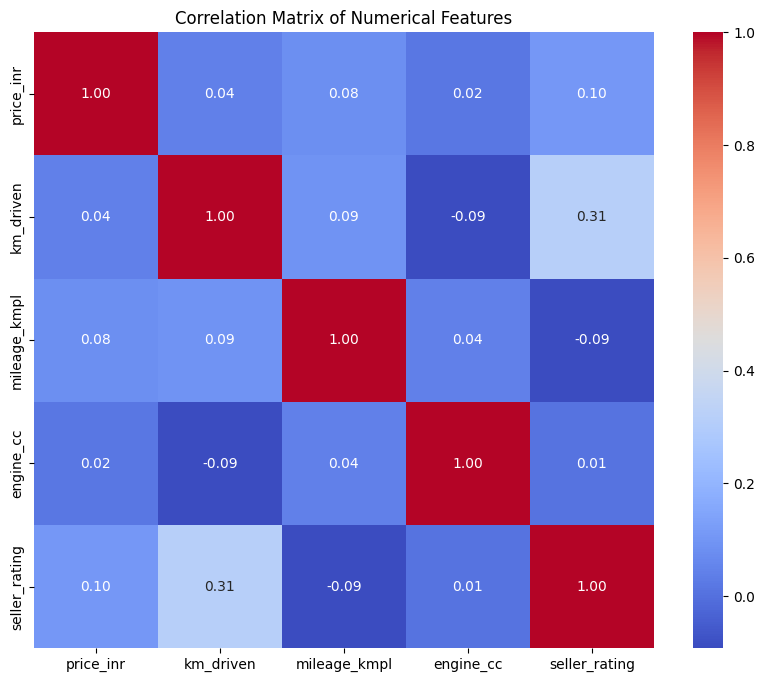

In [101]:
# Correlation matrix and heatmap for numerical features
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_cols_for_analysis].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

#### Numerical vs. Categorical Columns

/tmp/ipykernel_1041/1863756573.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='price_inr', y=col, data=df, ax=axes[i], palette='viridis')
/tmp/ipykernel_1041/1863756573.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='price_inr', y=col, data=df, ax=axes[i], palette='viridis')
/tmp/ipykernel_1041/1863756573.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='price_inr', y=col, data=df, ax=axes[i], palette='viridis')
/tmp/ipykernel_1041/1863756573.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated an

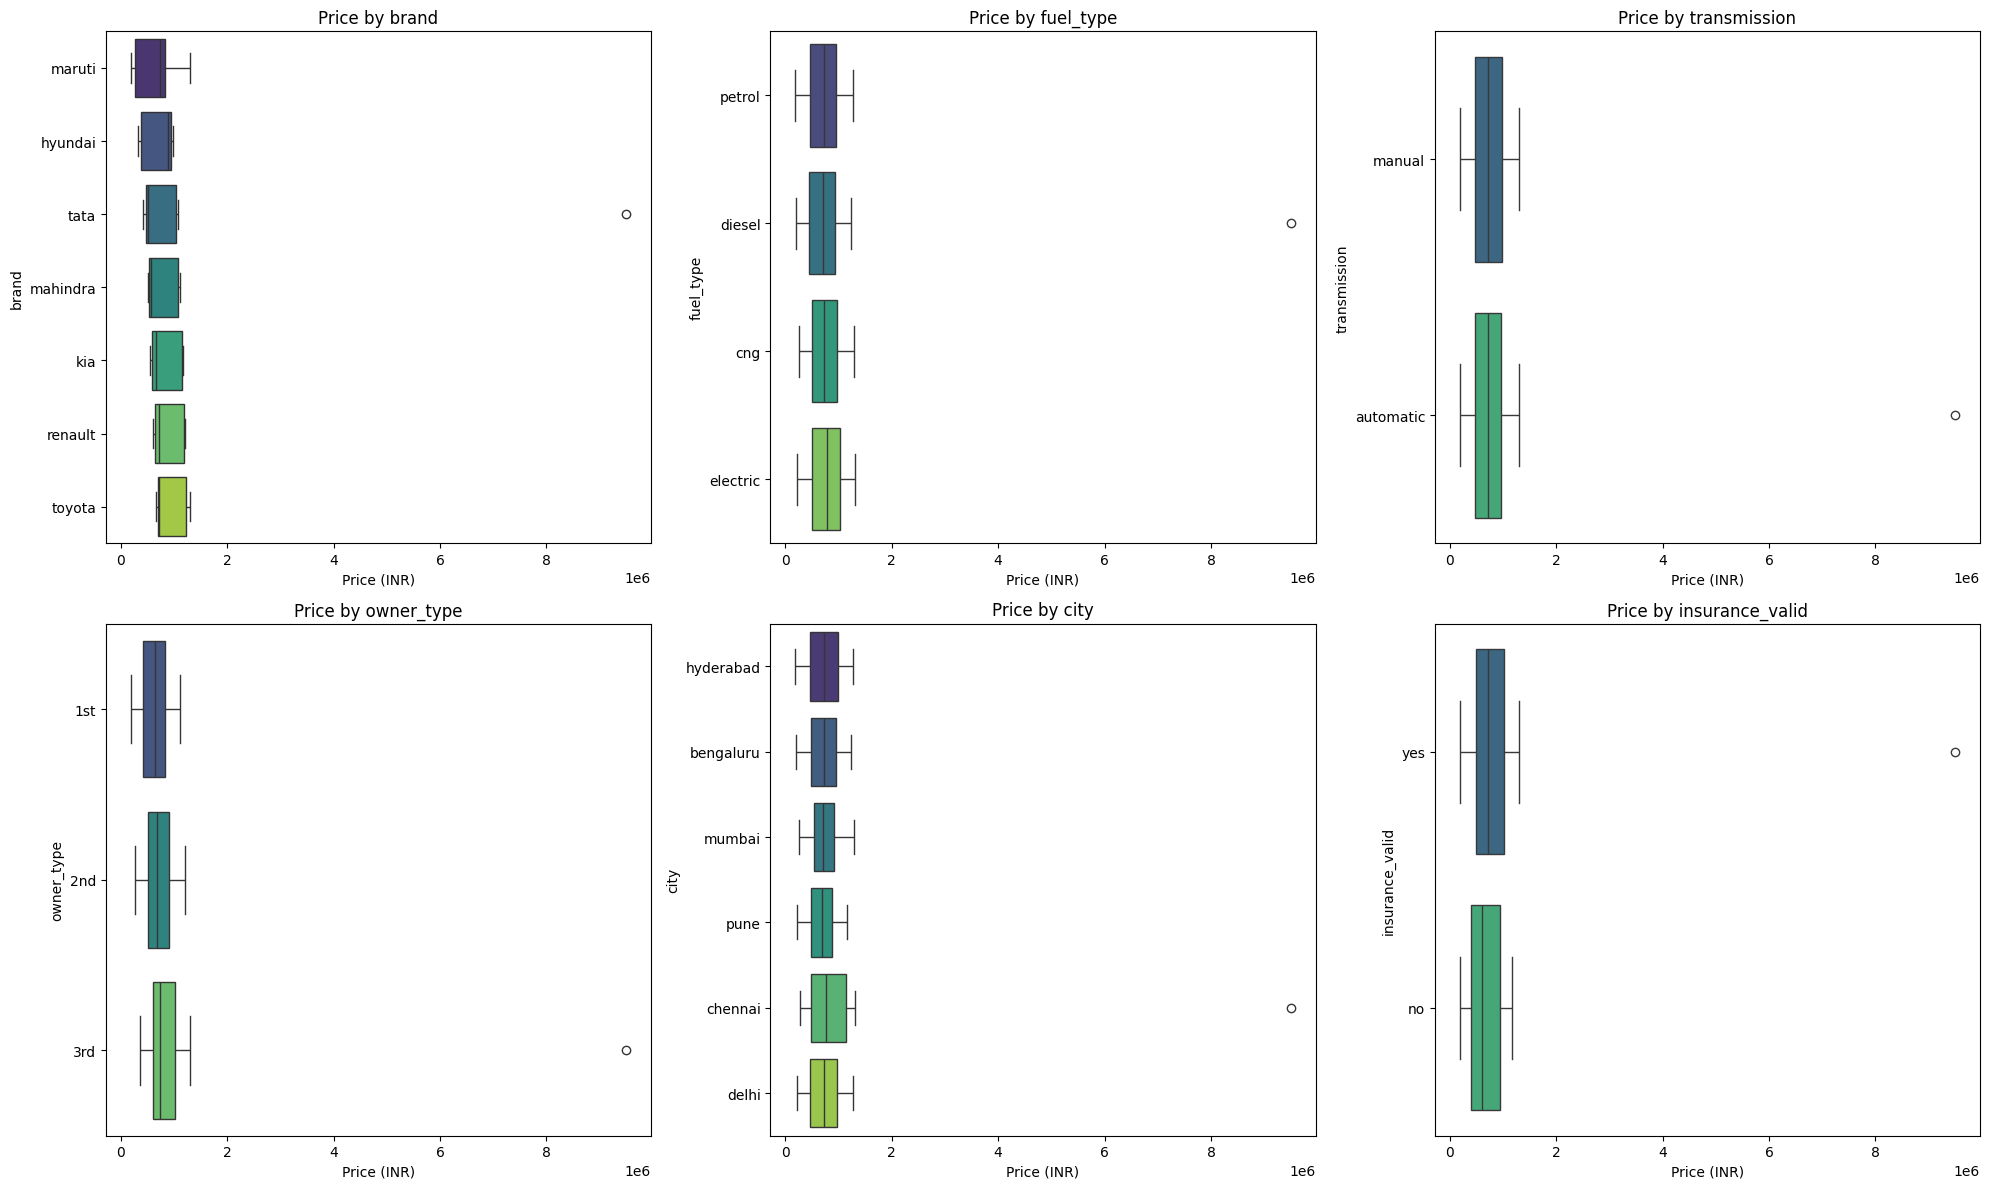

In [102]:
# Box plots for 'price_inr' against key categorical features

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for i, col in enumerate(['brand', 'fuel_type', 'transmission', 'owner_type', 'city', 'insurance_valid']):
    sns.boxplot(x='price_inr', y=col, data=df, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Price by {col}')
    axes[i].set_xlabel('Price (INR)')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

### Bivariate Analysis (Re-run with cleaned data)

#### Numerical vs. Numerical Columns

Pairplot of numerical columns:


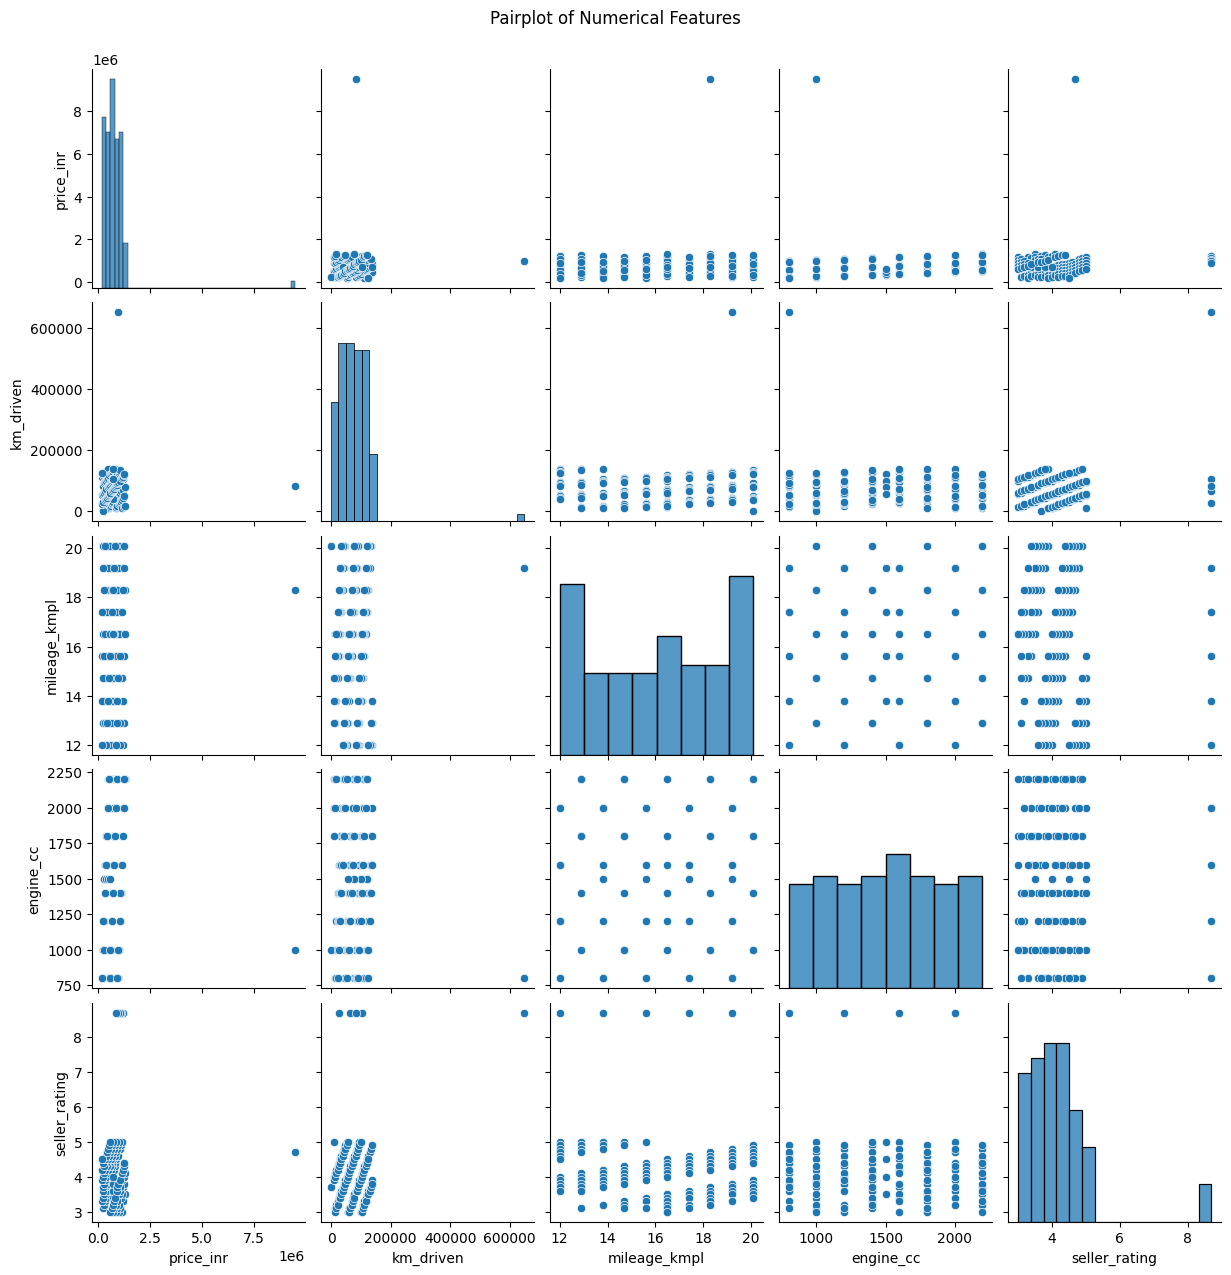

In [103]:
# Pairplot for selected numerical columns to visualize relationships
print("Pairplot of numerical columns:")
sns.pairplot(df[numerical_cols_for_analysis])
plt.suptitle('Pairplot of Numerical Features', y=1.02)
plt.show()

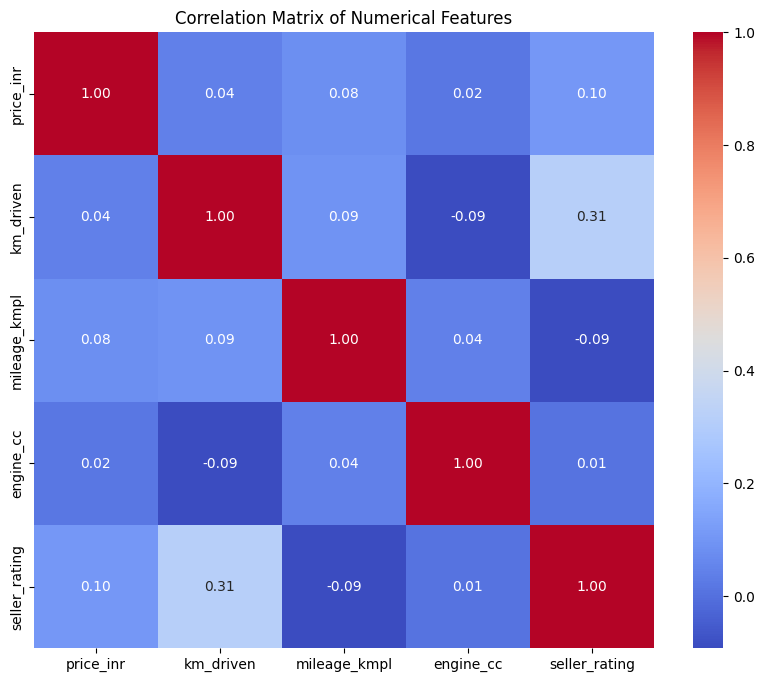

In [104]:
# Correlation matrix and heatmap for numerical features
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_cols_for_analysis].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

#### Numerical vs. Categorical Columns

In [105]:
df = pd.read_csv('/content/uncleaned_used_cars_eda.csv')

/tmp/ipykernel_1041/1863756573.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='price_inr', y=col, data=df, ax=axes[i], palette='viridis')
/tmp/ipykernel_1041/1863756573.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='price_inr', y=col, data=df, ax=axes[i], palette='viridis')
/tmp/ipykernel_1041/1863756573.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='price_inr', y=col, data=df, ax=axes[i], palette='viridis')
/tmp/ipykernel_1041/1863756573.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated an

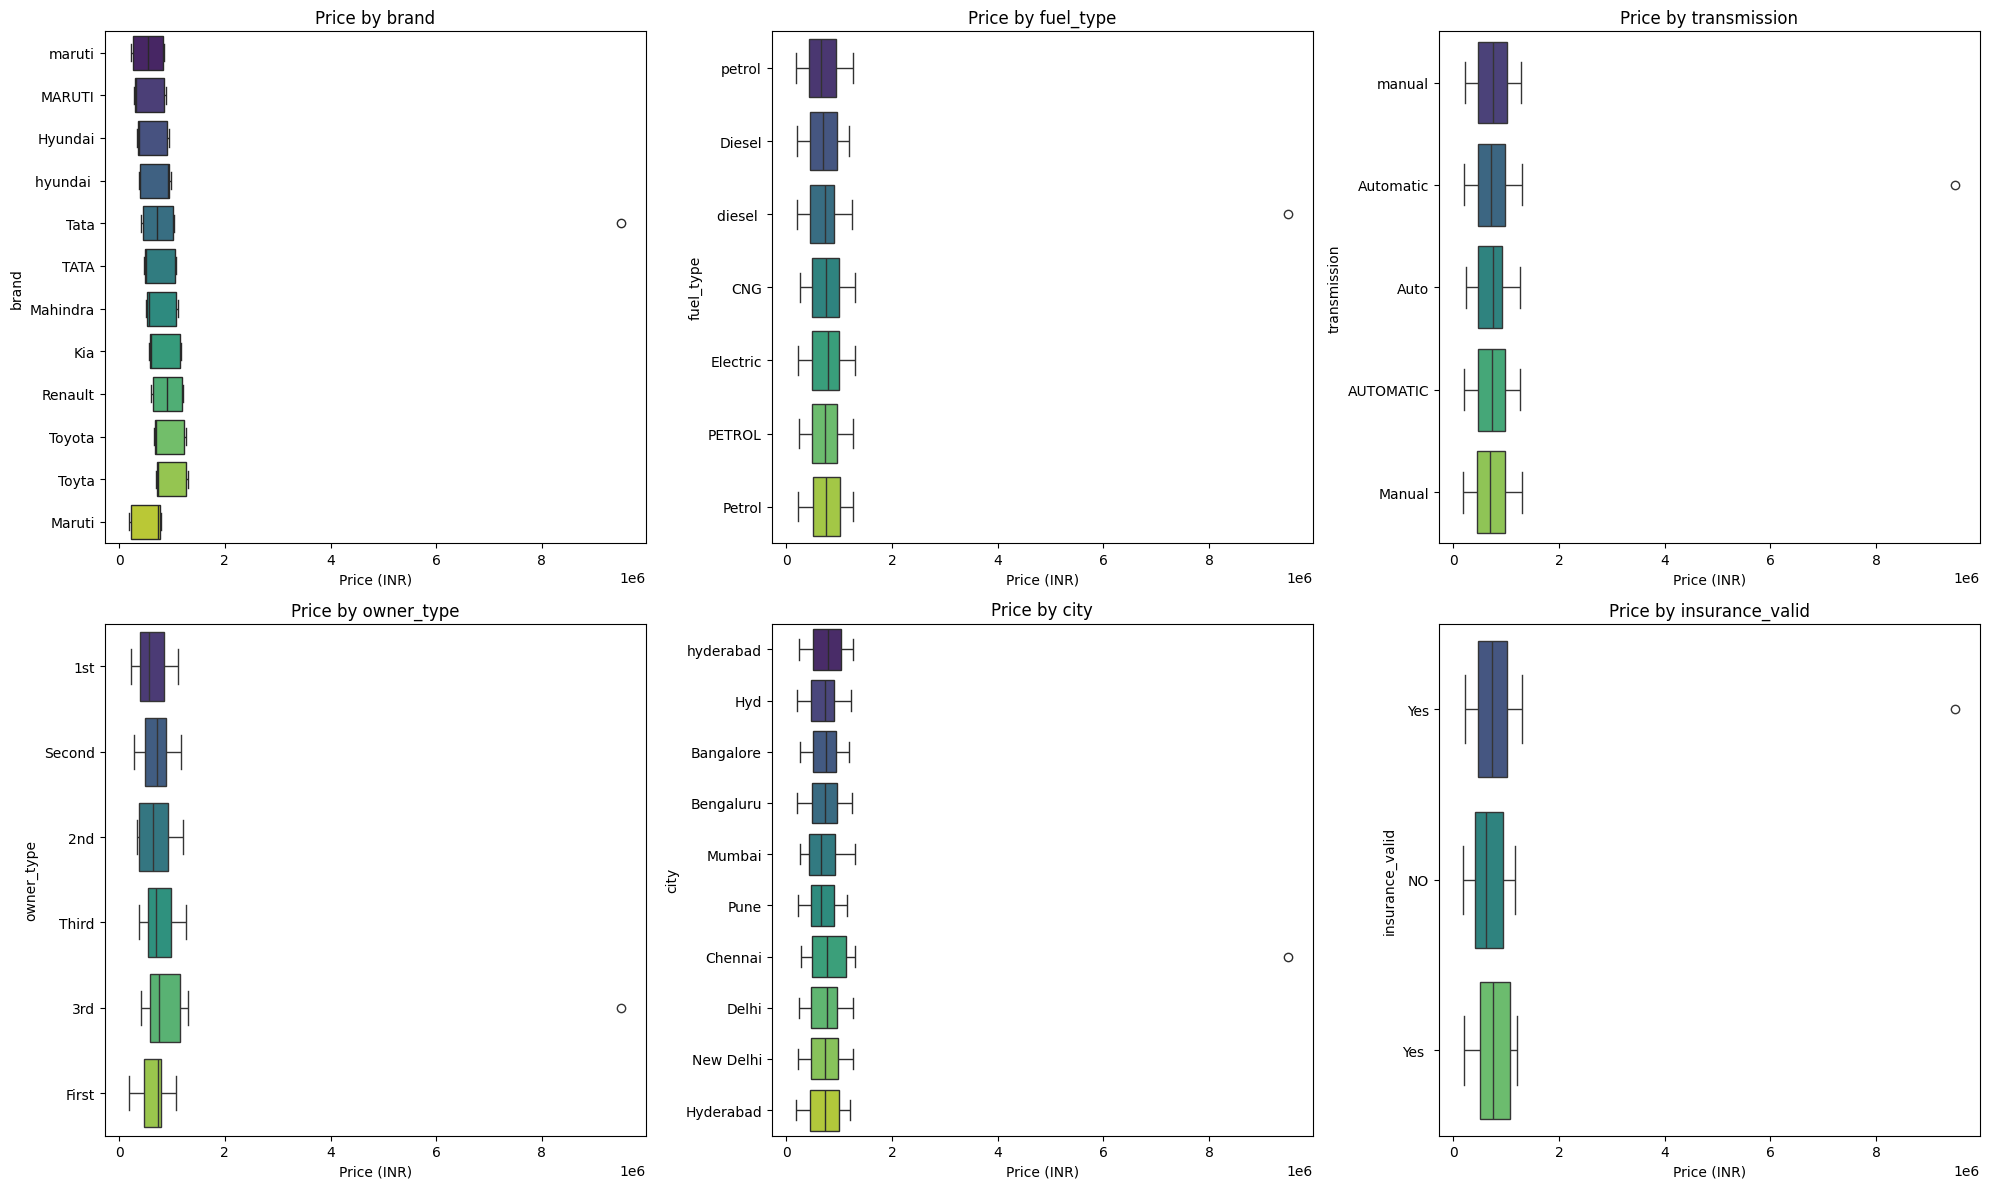

In [106]:
# Box plots for 'price_inr' against key categorical features

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for i, col in enumerate(['brand', 'fuel_type', 'transmission', 'owner_type', 'city', 'insurance_valid']):
    sns.boxplot(x='price_inr', y=col, data=df, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Price by {col}')
    axes[i].set_xlabel('Price (INR)')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()